# Setup

In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

# Inputs

In [2]:
years = 10
end_date = dt.datetime.now()
start_date = end_date - dt.timedelta(days = 365*years)

In [3]:
tickers = ['FFC.KA', 'MEBL.KA', 'PSO.KA', 'UBL.KA', 'DGKC.KA', 'INDU.KA', 'OGDC.KA']

In [4]:
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = start_date, end = end_date)
    adj_close_df[ticker] = data['Close']

/tmp/ipykernel_1692/1257715242.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = start_date, end = end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1692/1257715242.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = start_date, end = end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1692/1257715242.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = start_date, end = end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1692/1257715242.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = start_date, end = end_date)
[*********************100%***********************]  1 of 1 completed
/tmp

In [5]:
print(adj_close_df)

                FFC.KA     MEBL.KA      PSO.KA      UBL.KA     DGKC.KA  \
Date                                                                     
2016-11-14   34.327679   17.123575  138.223862  109.499496  157.948303   
2016-11-15   34.129631   16.885904  135.853012  108.272354  157.625870   
2016-11-16   34.110149   17.279194  136.072327  108.404701  158.109543   
2016-11-17   34.093910   17.259378  135.515305  107.590073  158.067108   
2016-11-18   34.003010   17.001907  135.389984  107.315117  158.627151   
...                ...         ...         ...         ...         ...   
2026-11-03  554.145386  526.570007  349.899994  412.670013  185.029999   
2026-11-04  562.520020  538.479980  359.470001  422.000000  195.009995   
2026-11-05  562.520020  555.020020  362.820007  422.000000  203.190002   
2026-11-06  562.619995  550.250000  355.100006  425.339996  200.410004   
2026-11-10  574.859985  570.780029  361.329987  445.299988  213.509995   

                INDU.KA     OGDC.KA  

In [6]:
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

              FFC.KA   MEBL.KA    PSO.KA    UBL.KA   DGKC.KA   INDU.KA  \
Date                                                                     
2016-11-15 -0.005786 -0.013977 -0.017301 -0.011270 -0.002043 -0.020964   
2016-11-16 -0.000571  0.023024  0.001613  0.001222  0.003064 -0.019018   
2016-11-17 -0.000476 -0.001147 -0.004102 -0.007543 -0.000268 -0.001798   
2016-11-18 -0.002670 -0.015030 -0.000925 -0.002559  0.003537 -0.015304   
2016-11-21 -0.002581  0.027251  0.011174 -0.004423 -0.005041  0.028500   
...              ...       ...       ...       ...       ...       ...   
2026-11-03  0.013562  0.013633  0.007890  0.006784  0.014535  0.004785   
2026-11-04  0.015000  0.022366  0.026983  0.022357  0.052533  0.005383   
2026-11-05  0.000000  0.030254  0.009276  0.000000  0.041091  0.004103   
2026-11-06  0.000178 -0.008631 -0.021507  0.007884 -0.013776  0.000362   
2026-11-10  0.021522  0.036631  0.017392  0.045859  0.063318  0.013138   

             OGDC.KA  
Date          

In [7]:
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

days = 5
confidence_interval = 0.95

[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714
 0.14285714]


# Method 1: Historical

In [8]:
historical_returns = (log_returns * weights).sum(axis =1)
print(historical_returns)

Date
2016-11-15   -0.010130
2016-11-16    0.001934
2016-11-17   -0.002089
2016-11-18   -0.005501
2016-11-21    0.009242
                ...   
2026-11-03    0.009662
2026-11-04    0.023843
2026-11-05    0.012103
2026-11-06   -0.003961
2026-11-10    0.030139
Length: 2584, dtype: float64


In [9]:
range_returns = historical_returns.rolling(window = days).sum()
range_returns = range_returns.dropna()
print(range_returns)

Date
2016-11-21   -0.006545
2016-11-22    0.001820
2016-11-23    0.001798
2016-11-24    0.002345
2016-11-25    0.005492
                ...   
2026-11-03    0.017475
2026-11-04    0.031408
2026-11-05    0.038957
2026-11-06    0.039755
2026-11-10    0.071786
Length: 2580, dtype: float64


In [10]:
VaR_hist = -np.percentile(range_returns, 100 - (confidence_interval * 100))*portfolio_value
print(VaR_hist)

45827.98378430332


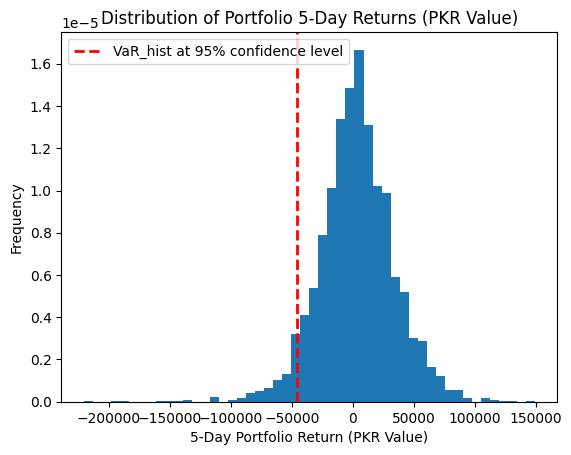

In [11]:
return_window = days
range_returns = historical_returns.rolling(window = return_window).sum()
range_returns = range_returns.dropna()

range_returns_PKR = range_returns * portfolio_value

plt.hist(range_returns_PKR.dropna(), bins = 50, density = True)
plt.xlabel(f'{return_window}-Day Portfolio Return (PKR Value)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {return_window}-Day Returns (PKR Value)')
plt.axvline(-VaR_hist, color = 'r', linestyle = 'dashed', linewidth = 2, label = f'VaR_hist at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()

# Method 2: Parametric

In [12]:
cov_matrix = log_returns.cov() * 252

In [13]:
portfolio_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)

In [14]:
confidence_levels = [0.9, 0.95, 0.99]

In [15]:
VaRs = []

for c1 in confidence_levels:
  VaR_parametric = portfolio_value * portfolio_std_dev * norm.ppf(c1) *np.sqrt(days/252)
  VaRs.append(VaR_parametric)

In [16]:
print(f'{'Confidence Level':<20} {"Value at Risk":<20}')
print('-' * 40)

for c1, VaR_parametric in zip(confidence_levels, VaRs):
  print(f'{c1 * 100:>6.0f}%: {'':<8} PKR{VaR_parametric:>10,.2f}')

Confidence Level     Value at Risk       
----------------------------------------
    90%:          PKR 40,772.48
    95%:          PKR 52,330.92
    99%:          PKR 74,012.61


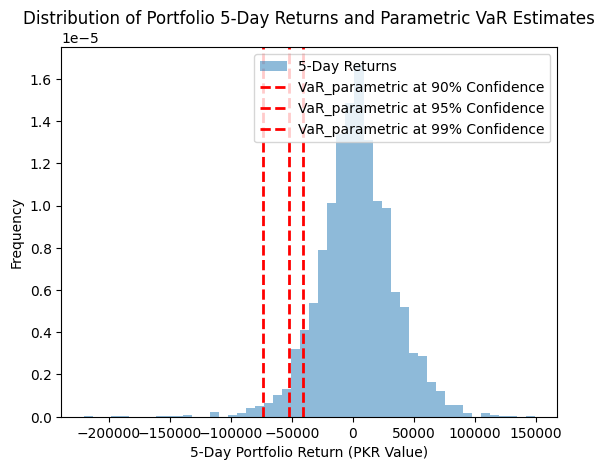

In [17]:
historical_x_day_returns_PKR = range_returns * portfolio_value
plt.hist(historical_x_day_returns_PKR, bins = 50, density = True, alpha=0.5, label=f'{days}-Day Returns')
for c1, VaR_parametric in zip(confidence_levels, VaRs):
  plt.axvline(x=-VaR_parametric, color = 'r', linestyle = 'dashed', linewidth = 2, label = 'VaR_parametric at {}% Confidence'.format(int(c1 * 100)))

plt.xlabel(f'{days}-Day Portfolio Return (PKR Value)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {days}-Day Returns and Parametric VaR Estimates')
plt.legend()
plt.show()

# Method 3: Monte Carlo

In [18]:
def expected_returns(weights, log_returns):
  return np.sum(log_returns.mean() * weights)

In [19]:
def standard_deviation(weights, cov_matrix):
  variance = weights.T @ cov_matrix @ weights
  return np.sqrt(variance)

In [20]:
cov_matrix_monte_carlo = log_returns.cov() * 252
print(cov_matrix_monte_carlo)

           FFC.KA   MEBL.KA    PSO.KA    UBL.KA   DGKC.KA   INDU.KA   OGDC.KA
FFC.KA   0.059623  0.021258  0.035085  0.022440  0.036579  0.015194  0.029060
MEBL.KA  0.021258  0.083191  0.039250  0.031923  0.040966  0.017272  0.032098
PSO.KA   0.035085  0.039250  0.116801  0.042115  0.076591  0.027072  0.069552
UBL.KA   0.022440  0.031923  0.042115  0.420665  0.052083  0.020088  0.032426
DGKC.KA  0.036579  0.040966  0.076591  0.052083  0.165039  0.030509  0.054953
INDU.KA  0.015194  0.017272  0.027072  0.020088  0.030509  0.063114  0.018816
OGDC.KA  0.029060  0.032098  0.069552  0.032426  0.054953  0.018816  0.100615


In [21]:
portfolio_expected_return = expected_returns(weights, log_returns)
portfolio_std_dev = standard_deviation(weights, cov_matrix_monte_carlo)

In [22]:
def random_z_score():
  return np.random.normal(0,1)

In [23]:
def scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days):
  return portfolio_value * portfolio_expected_return * days + portfolio_value * portfolio_std_dev * z_score * np.sqrt(days/252)

In [24]:
 simulations = 10000
 ScenarioReturn = []

 for i in range(simulations):
   z_score = random_z_score()
   ScenarioReturn.append(scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days))

In [25]:
VaR_monte_carlo = -np.percentile(ScenarioReturn, 100*(1- confidence_interval))
print(VaR_monte_carlo)

48682.73262130457


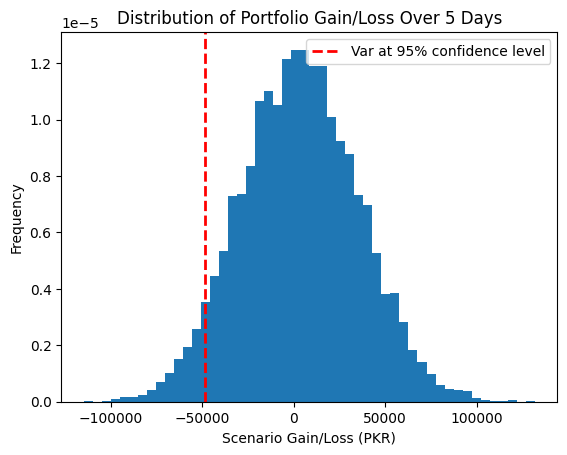

In [26]:
plt.hist(ScenarioReturn, bins = 50, density = True)
plt.xlabel('Scenario Gain/Loss (PKR)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio Gain/Loss Over {days} Days')
plt.axvline(-VaR_monte_carlo, color='r', linestyle='dashed', linewidth=2, label=f'Var at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()

In [27]:
losses_mc = -np.array(ScenarioReturn)

VaR_95_mc = np.percentile(losses_mc, 95)

CVaR_95_mc = losses_mc[
    losses_mc >= VaR_95_mc
].mean()

print(f"Monte Carlo VaR: PKR {VaR_95_mc:,.2f}")
print(f"Monte Carlo CVaR: PKR {CVaR_95_mc:,.2f}")

Monte Carlo VaR: PKR 48,682.73
Monte Carlo CVaR: PKR 61,369.57
